# 03 用户分群：RFM 价值分层与 K 均值聚类

两种分群方法，回答两个不同的问题：

| 方法 | 回答的问题 | 适用对象 |
|---|---|---|
| **RFM 价值分层**（规则法） | 哪些用户最有价值、哪些快流失了？ | 有过购买的用户 |
| **K 均值聚类**（无监督学习） | 用户在行为上自然分成哪几类？ | 全部用户 |

> **口径说明：** 这个数据集没有订单金额字段，所以 RFM 里的 M（消费金额）无法计算，这里使用 **R（最近一次购买距今天数）+ F（购买天数）** 的 RF 模型。面试时主动说明这一点，并说明有金额数据时如何补上 M。

In [21]:
# 在 Google Colab 上运行时先执行这一格；在自己电脑上运行会自动跳过
import os, sys, subprocess
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/ecommerce-user-behavior/notebooks")
    subprocess.run("pip -q install duckdb xgboost", shell=True, check=True)
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True, check=True)
    import matplotlib.font_manager as fm
    for f in fm.findSystemFonts():
        if "NotoSansCJK" in f:
            fm.fontManager.addfont(f)
    print("Colab 环境准备完成，当前目录：", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab 环境准备完成，当前目录： /content/drive/MyDrive/ecommerce-user-behavior/notebooks


In [22]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
import config, utils

utils.setup_plot()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
con = utils.connect()
BLUE, ORANGE = "#3B6FB6", "#E07B39"

## 1. 用 SQL 构建用户特征表

In [23]:
users = con.execute(f'''
    SELECT
        user_id,
        COUNT(*) FILTER (WHERE behavior_type = 'pv')                     AS pv_cnt,
        COUNT(*) FILTER (WHERE behavior_type = 'fav')                    AS fav_cnt,
        COUNT(*) FILTER (WHERE behavior_type = 'cart')                   AS cart_cnt,
        COUNT(*) FILTER (WHERE behavior_type = 'buy')                    AS buy_cnt,
        COUNT(DISTINCT event_date)                                       AS active_days,
        COUNT(DISTINCT event_date) FILTER (WHERE behavior_type = 'buy')  AS buy_days,
        COUNT(DISTINCT item_id)                                          AS n_items,
        COUNT(DISTINCT category_id)                                      AS n_categories,
        date_diff('day', MAX(event_date) FILTER (WHERE behavior_type = 'buy'),
                  DATE '{config.REFERENCE_DATE}')                        AS recency_buy,
        date_diff('day', MAX(event_date), DATE '{config.REFERENCE_DATE}') AS recency_active
    FROM ub
    GROUP BY user_id
''').df()
users.to_parquet(config.USER_FEATURES_PARQUET, index=False)
print(f"用户数：{len(users):,}")
users.drop(columns="user_id").describe().T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

用户数：99,057


,count,mean,std,min,25%,50%,75%,max
pv_cnt,"99,057.000",90.514,80.439,0.000,34.000,66.000,121.000,827.000
fav_cnt,"99,057.000",2.925,7.837,0.000,0.000,0.000,2.000,343.000
cart_cnt,"99,057.000",5.591,7.649,0.000,0.000,3.000,8.000,153.000
buy_cnt,"99,057.000",2.030,2.682,0.000,0.000,1.000,3.000,72.000
active_days,"99,057.000",7.047,1.678,1.000,6.000,7.000,9.000,9.000
buy_days,"99,057.000",1.348,1.355,0.000,0.000,1.000,2.000,9.000
n_items,"99,057.000",76.662,63.939,1.000,31.000,58.000,102.000,626.000
n_categories,"99,057.000",24.475,16.550,1.000,13.000,21.000,32.000,211.000
recency_buy,"67,293.000",3.563,2.421,1.000,1.000,3.000,5.000,9.000
recency_active,"99,057.000",1.024,0.184,1.000,1.000,1.000,1.000,9.000


## 2. RF 价值分层

**打分规则：**
- R：最近一次购买距今天数 ≤ 购买用户的中位数，记为"近"，否则为"远"
- F：购买天数 ≥ 2（有复购），记为"高频"，否则为"低频"

按"近/远 × 高频/低频"分成四类，每类对应不同的运营动作。

,用户数,平均购买次数,平均购买天数,平均距今天数,占比,购买次数贡献,运营建议
分层,,,,,,,
重要价值用户,26654,4.570,2.953,1.712,0.396,0.606,会员权益、新品优先购，维持高频购买
重要保持用户,10383,3.548,2.366,5.213,0.154,0.183,曾经常买但近期没来，用优惠券和个性化推送召回
重要发展用户,12020,1.409,1.000,1.893,0.179,0.084,刚买过一次，推荐相关商品，引导第二次购买
重要挽留用户,18236,1.396,1.000,6.429,0.271,0.127,很久前买过一次，低成本触达，评估召回价值


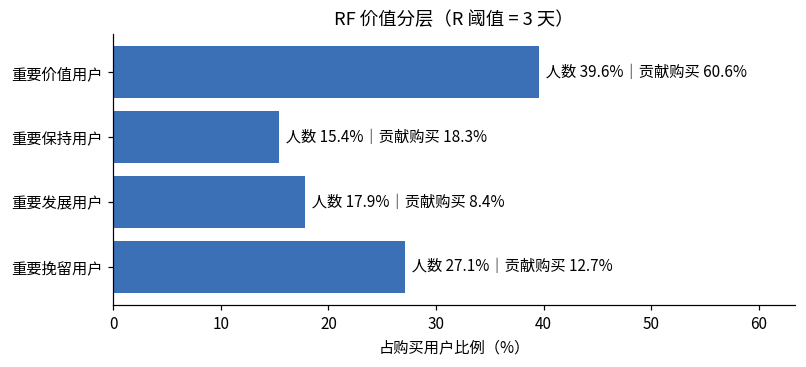

In [24]:
buyers = users[users["buy_cnt"] > 0].copy()
r_threshold = buyers["recency_buy"].median()
buyers["R"] = np.where(buyers["recency_buy"] <= r_threshold, "近", "远")
buyers["F"] = np.where(buyers["buy_days"] >= 2, "高频", "低频")

segment_map = {
    ("近", "高频"): "重要价值用户",
    ("远", "高频"): "重要保持用户",
    ("近", "低频"): "重要发展用户",
    ("远", "低频"): "重要挽留用户",
}
action_map = {
    "重要价值用户": "会员权益、新品优先购，维持高频购买",
    "重要保持用户": "曾经常买但近期没来，用优惠券和个性化推送召回",
    "重要发展用户": "刚买过一次，推荐相关商品，引导第二次购买",
    "重要挽留用户": "很久前买过一次，低成本触达，评估召回价值",
}
buyers["分层"] = [segment_map[(r, f)] for r, f in zip(buyers["R"], buyers["F"])]

rf = (buyers.groupby("分层")
      .agg(用户数=("user_id", "count"),
           平均购买次数=("buy_cnt", "mean"),
           平均购买天数=("buy_days", "mean"),
           平均距今天数=("recency_buy", "mean"))
      .reindex(list(action_map)))
rf["占比"] = rf["用户数"] / rf["用户数"].sum()
rf["购买次数贡献"] = buyers.groupby("分层")["buy_cnt"].sum().reindex(rf.index) / buyers["buy_cnt"].sum()
rf["运营建议"] = rf.index.map(action_map)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(rf.index[::-1], rf["占比"][::-1] * 100, color=BLUE)
for i, (s, c) in enumerate(zip(rf["占比"][::-1], rf["购买次数贡献"][::-1])):
    ax.text(s * 100, i, f"  人数 {s:.1%}｜贡献购买 {c:.1%}", va="center")
ax.set_xlim(0, rf["占比"].max() * 100 * 1.6)
ax.set_xlabel("占购买用户比例（%）")
ax.set_title(f"RF 价值分层（R 阈值 = {r_threshold:.0f} 天）")
_ = utils.save_fig(fig, "03_RF价值分层")
rf

## 3. K 均值聚类：用户行为分群

**特征选择：** 浏览、收藏、加购、购买次数，活跃天数，浏览类目数。
**预处理：** 次数类特征右偏严重，先做 `log(1 + x)` 变换，再标准化，避免浏览次数这种量级大的特征主导距离计算。
**选 K：** 同时看肘部法则（组内平方和）和轮廓系数。

,K,组内平方和,轮廓系数
0,2,"399,603.892",0.281
1,3,"332,759.041",0.266
2,4,"292,903.906",0.207
3,5,"268,526.683",0.204
4,6,"249,312.874",0.203
5,7,"233,834.368",0.177
6,8,"221,295.621",0.178


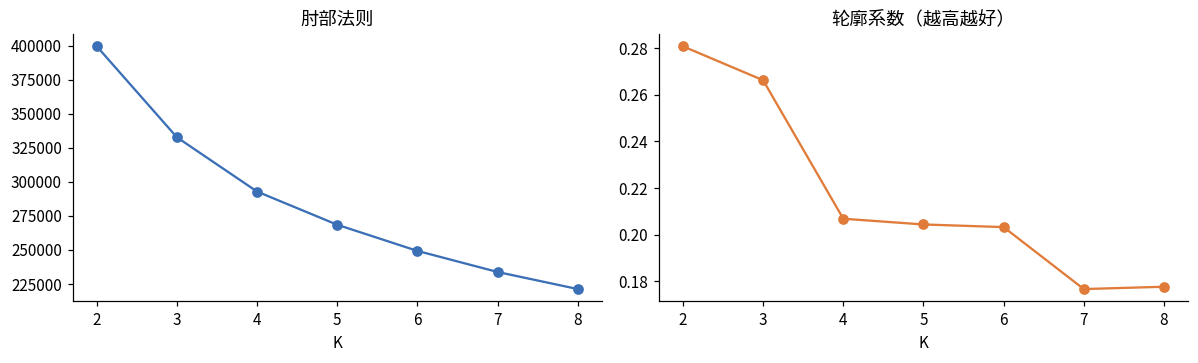

In [25]:
feature_cols = ["pv_cnt", "fav_cnt", "cart_cnt", "buy_cnt", "active_days", "n_categories"]
X_raw = users[feature_cols].astype(float).copy()
for c in ["pv_cnt", "fav_cnt", "cart_cnt", "buy_cnt", "n_categories"]:
    X_raw[c] = np.log1p(X_raw[c])
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)

rng = np.random.default_rng(config.RANDOM_STATE)
fit_idx = rng.choice(len(X), size=min(len(X), 300_000), replace=False)    # 用户太多时抽样拟合
sil_idx = rng.choice(len(X), size=min(len(X), 20_000), replace=False)     # 轮廓系数计算量大，抽样计算

k_range = range(2, 9)
scores = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=config.RANDOM_STATE).fit(X[fit_idx])
    sil = silhouette_score(X[sil_idx], km.predict(X[sil_idx]))
    scores.append({"K": k, "组内平方和": km.inertia_, "轮廓系数": sil})
scores = pd.DataFrame(scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(scores["K"], scores["组内平方和"], marker="o", color=BLUE)
axes[0].set_title("肘部法则")
axes[1].plot(scores["K"], scores["轮廓系数"], marker="o", color=ORANGE)
axes[1].set_title("轮廓系数（越高越好）")
for ax in axes:
    ax.set_xlabel("K")
fig.tight_layout()
_ = utils.save_fig(fig, "03_选择K值")
scores

In [26]:
# 默认在 3 到 6 之间选轮廓系数最高的 K（太少没有区分度，太多不好解释）。
# 看完上面的图，如果你认为别的 K 更合理，直接把 K_CHOSEN 改成那个数字。
K_CHOSEN = None
if K_CHOSEN is None:
    K_CHOSEN = int(scores[scores["K"].between(3, 6)].sort_values("轮廓系数", ascending=False)["K"].iloc[0])

kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=config.RANDOM_STATE).fit(X[fit_idx])
users["cluster"] = kmeans.predict(X)
chosen_sil = float(scores.loc[scores["K"] == K_CHOSEN, "轮廓系数"].iloc[0])
print(f"选择 K = {K_CHOSEN}，轮廓系数 = {chosen_sil:.3f}")

选择 K = 3，轮廓系数 = 0.266


,用户数,占比,平均浏览,平均收藏,平均加购,平均购买,平均活跃天数,平均浏览类目数,购买用户占比,加购到购买比
cluster,,,,,,,,,,
0,39440,0.398,123.184,0.371,9.809,2.812,8.015,31.533,0.806,0.287
2,19755,0.199,138.735,12.466,4.397,2.474,8.000,35.397,0.744,0.563
1,39862,0.402,34.293,0.725,2.009,1.035,5.617,12.078,0.522,0.515


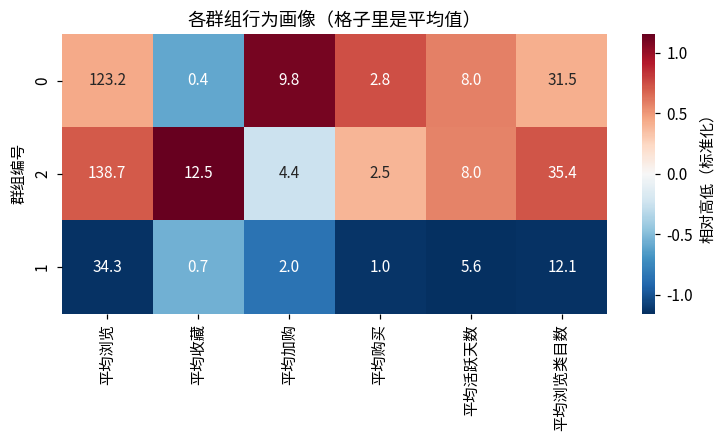

In [27]:
profile = (users.groupby("cluster")
           .agg(用户数=("user_id", "count"),
                平均浏览=("pv_cnt", "mean"),
                平均收藏=("fav_cnt", "mean"),
                平均加购=("cart_cnt", "mean"),
                平均购买=("buy_cnt", "mean"),
                平均活跃天数=("active_days", "mean"),
                平均浏览类目数=("n_categories", "mean"),
                购买用户占比=("buy_cnt", lambda s: (s > 0).mean())))
profile.insert(1, "占比", profile["用户数"] / profile["用户数"].sum())
profile["加购到购买比"] = profile["平均购买"] / profile["平均加购"].replace(0, np.nan)
profile = profile.sort_values("平均购买", ascending=False)

z = (profile[["平均浏览", "平均收藏", "平均加购", "平均购买", "平均活跃天数", "平均浏览类目数"]]
     .apply(lambda c: (c - c.mean()) / (c.std() if c.std() > 0 else 1)))
fig, ax = plt.subplots(figsize=(8, 0.6 * K_CHOSEN + 1.5))
sns.heatmap(z, annot=profile[z.columns].round(1), fmt="", cmap="RdBu_r", center=0, ax=ax,
            cbar_kws={"label": "相对高低（标准化）"})
ax.set_ylabel("群组编号")
ax.set_title("各群组行为画像（格子里是平均值）")
_ = utils.save_fig(fig, "03_聚类画像")
profile

### 给每个群组起名字

看上面的画像表和热力图，按特征给每个群组起一个业务上好理解的名字，然后填进下面的 `CLUSTER_NAMES`。常见的命名思路：

- 各项都高、购买最多 → "高价值活跃用户"
- 浏览很多、加购也多，但购买少 → "犹豫型用户"（重点做促转化）
- 浏览类目多、互动少 → "随便逛逛型用户"
- 活跃天数少、各项都低 → "低活跃用户"（重点做召回）

编号顺序每次运行可能不同，一定要对照画像表填写。

In [28]:
low = profile["平均浏览"].idxmin()                                   # 浏览最少的是低频用户
fav = profile.drop(low)["平均收藏"].idxmax()                          # 剩下两组里收藏最多的是收藏型
cart = [c for c in profile.index if c not in (low, fav)][0]          # 最后一组是加购型
CLUSTER_NAMES = {cart: "加购型主力用户", fav: "收藏型深度浏览用户", low: "低频轻度用户"}
users["群组名称"] = users["cluster"].map(CLUSTER_NAMES)
profile.index = profile.index.map(CLUSTER_NAMES)

# 卡方检验：不同群组的购买用户占比是否有显著差异
table = pd.crosstab(users["群组名称"], users["buy_cnt"] > 0)
chi2, p_value, dof, _ = stats.chi2_contingency(table)
cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
print(f"卡方检验：卡方值 = {chi2:,.1f}，自由度 = {dof}，P 值 = {p_value:.3g}，克莱姆 V 系数 = {cramers_v:.3f}")
print("克莱姆 V 系数衡量关联强度：0.1 左右为弱，0.3 左右为中等，0.5 以上为强。")

卡方检验：卡方值 = 7,840.8，自由度 = 2，P 值 = 0，克莱姆 V 系数 = 0.281
克莱姆 V 系数衡量关联强度：0.1 左右为弱，0.3 左右为中等，0.5 以上为强。


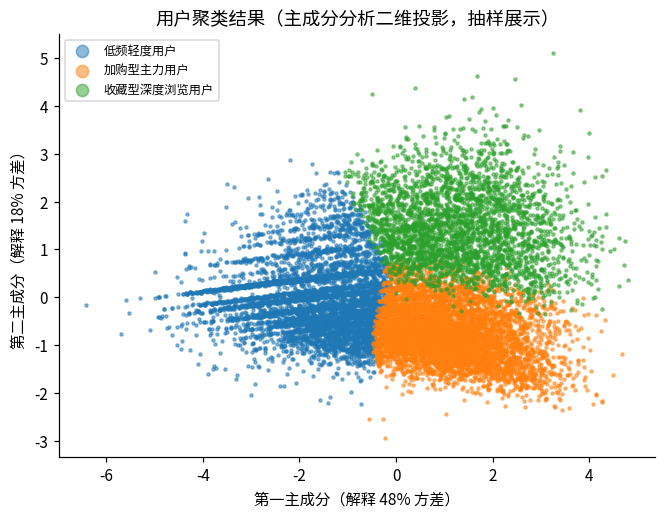

In [29]:
# 主成分分析降到二维，直观看聚类效果
pca = PCA(n_components=2, random_state=config.RANDOM_STATE)
plot_idx = rng.choice(len(X), size=min(len(X), 15_000), replace=False)
coords = pca.fit(X[fit_idx]).transform(X[plot_idx])

fig, ax = plt.subplots(figsize=(7, 5))
for name, g in pd.DataFrame({"x": coords[:, 0], "y": coords[:, 1],
                             "name": users["群组名称"].values[plot_idx]}).groupby("name"):
    ax.scatter(g["x"], g["y"], s=4, alpha=0.5, label=name)
ax.set_xlabel(f"第一主成分（解释 {pca.explained_variance_ratio_[0]:.0%} 方差）")
ax.set_ylabel(f"第二主成分（解释 {pca.explained_variance_ratio_[1]:.0%} 方差）")
ax.set_title("用户聚类结果（主成分分析二维投影，抽样展示）")
ax.legend(markerscale=4, fontsize=8)
_ = utils.save_fig(fig, "03_聚类二维投影")

In [30]:
profile.to_csv(config.RESULTS_DIR / "03_聚类画像.csv", encoding="utf-8-sig")
rf.to_csv(config.RESULTS_DIR / "03_RF分层.csv", encoding="utf-8-sig")

utils.update_summary("03_用户分群", {
    "购买用户数": int(len(buyers)),
    "RF分层_R阈值天数": float(r_threshold),
    "RF分层_用户占比": {k: round(float(v), 4) for k, v in rf["占比"].items()},
    "RF分层_购买次数贡献": {k: round(float(v), 4) for k, v in rf["购买次数贡献"].items()},
    "聚类K值": K_CHOSEN,
    "聚类轮廓系数": round(chosen_sil, 4),
    "聚类_各群组占比": {str(k): round(float(v), 4) for k, v in profile["占比"].items()},
    "聚类_各群组购买用户占比": {str(k): round(float(v), 4) for k, v in profile["购买用户占比"].items()},
    "聚类_卡方检验P值": float(p_value),
    "聚类_克莱姆V系数": round(float(cramers_v), 4),
})
print("已写入 results/summary.json")

已写入 results/summary.json


## 小结（跑完真实数据后填写）

- RF 分层：哪类用户人数少但贡献大？哪类最需要召回？
- 聚类：分成了几类，每类的特征和运营建议是什么？
- 局限：没有金额数据，聚类结果对特征选择和 K 值比较敏感。

下一步：`04_购买预测模型.ipynb`